# Z2 vs sigma â€” dependence on the bond cutoff R and on Anderson disorder W

L=20, repulsion kappa_shift = 3 r0, Delta=2, 100 realizations.
- `01_z2_vs_sigma_cutoff_R/`: W=0, R = 1.05, 1.1, 1.15, 1.2, 1.25 (r0)
- `02_z2_vs_sigma_anderson_W/`: R=1.3, W = 2, 4, 6, 8, 10, 12
- Reference R=1.3, W=0: `appendix/finite_size_scaling/results_2d_v_3r0/*_L20.h5`

Copy the `results_*` folders from the cluster into the corresponding subfolder before running.

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import matplotlib
import cmasher as csh

HERE = Path.cwd()
FSS_DIR = HERE.parents[1] / "appendix" / "finite_size_scaling"
sys.path.append(str(FSS_DIR))
from load_files_from_cluster import load_cluster_results

matplotlib.rcParams.update(
    {
        "font.size": 10,
        "text.usetex": True,
        "font.family": "serif",
        "font.serif": ["Times"],
    }
)
aps_figwidth = 6.6

In [3]:
# â”€â”€ run parameters (must match the submitted jobs) â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
L = 20
KSHIFT = 3.0
DELTA = 2.0
SIGMA_RANGE = "0.0-0.5"
R_REF, W_REF = 1.3, 0.0

R_VALUES = [1.05, 1.1, 1.15, 1.2, 1.25]
W_VALUES = [2.0, 4.0, 6.0, 8.0, 10.0, 12.0]


def results_dir(folder, R, W):
    return HERE / folder / (
        f"results_2d_L{L}_kshift{KSHIFT}r0_R{R}_W{W}_Delta{DELTA}_sigma{SIGMA_RANGE}"
    )


def load_or_none(path, pattern):
    # skip runs that are not copied back yet instead of crashing the notebook
    try:
        return load_cluster_results(path, pattern)
    except FileNotFoundError as e:
        print(f"!! missing: {e}")
        return None


def check_attrs(out, **expected):
    # make sure we are plotting what we think we are plotting
    attrs = out["attrs"]
    for key, val in expected.items():
        assert np.isclose(attrs[key], val), f"{key}={attrs[key]} != {val}"

In [4]:
# â”€â”€ reference: R=1.3, W=0 (old finite-size run) â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
ref = load_or_none(FSS_DIR / "results_2d_v_3r0", f"results_sigma*_num_reals_100_L{L}.h5")
check_attrs(ref, L=L, W=W_REF, Delta=DELTA, kappa_shift=KSHIFT / L, bond_distance=R_REF / L)

# â”€â”€ analysis 1: cutoff R, W=0 â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
out_R = {R_REF: ref}
for R in R_VALUES:
    out = load_or_none(results_dir("01_z2_vs_sigma_cutoff_R", R, 0.0), "sigma_*.h5")
    if out is not None:
        check_attrs(out, L=L, W=0.0, Delta=DELTA, kappa_shift_r0=KSHIFT, R_cutoff=R)
        out_R[R] = out

# â”€â”€ analysis 2: Anderson W, R=1.3 â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
out_W = {W_REF: ref}
for W in W_VALUES:
    out = load_or_none(results_dir("02_z2_vs_sigma_anderson_W", R_REF, W), "sigma_*.h5")
    if out is not None:
        check_attrs(out, L=L, W=W, Delta=DELTA, kappa_shift_r0=KSHIFT, R_cutoff=R_REF)
        out_W[W] = out

Loaded 99 files from /Users/laura/Desktop/TAI-localizer/appendix/finite_size_scaling/results_2d_v_3r0
sigma range: [0.000,0.025]
Parameters for the calculation:
  A: 1.0
  B: 1.0
  Delta: 2
  L: 20
  W: 0
  beta: 1
  bond_distance: 0.065
  bond_lengthscale: 0.05
  bond_power: 1
  hadamard_disorder: 0.15
  kappa: 1
  kappa_shift: 0.15000000000000002
  num_reals: 100
  par_variable_name: sigma
  sigma: 0.00010204081632653062
Outputs obtained from the calculation: ['z2']
Loaded 50 files from /Users/laura/Desktop/TAI-localizer/cluster_code/sigma_scan_2D_L20_kshift3r0/01_z2_vs_sigma_cutoff_R/results_2d_L20_kshift3.0r0_R1.05_W0.0_Delta2.0_sigma0.0-0.5
sigma range: [0.000,0.025]
Parameters for the calculation:
  A: 1.0
  B: 1.0
  Delta: 2.0
  E0: 0.0
  L: 20
  R_cutoff: 1.05
  W: 0.0
  beta: 1
  bond_distance: 0.052500000000000005
  bond_lengthscale: 0.05
  bond_power: 1
  hadamard_disorder: 0.15
  kappa: 1
  kappa_shift: 0.15000000000000002
  kappa_shift_r0: 3.0
  n_iterations_move: 3
  num_

In [5]:
def curve(out):
    # sigma in units of r0, <z2> and its standard error over realizations
    sigma_r0 = out["sigma_values"] * L
    z2 = np.asarray(out["z2"], dtype=float)
    mean = z2.mean(axis=1)
    sem = z2.std(axis=1, ddof=1) / np.sqrt(z2.shape[1])
    return sigma_r0, mean, sem


for name, data in [("R", out_R), ("W", out_W)]:
    for key, out in sorted(data.items()):
        n_sig, n_real = np.shape(out["z2"])
        print(f"{name}={key}: {n_sig} sigma values x {n_real} realizations")

R=1.05: 50 sigma values x 100 realizations
R=1.1: 50 sigma values x 100 realizations
R=1.15: 50 sigma values x 100 realizations
R=1.2: 50 sigma values x 100 realizations
R=1.25: 50 sigma values x 100 realizations
R=1.3: 99 sigma values x 100 realizations
W=0.0: 99 sigma values x 100 realizations
W=2.0: 50 sigma values x 100 realizations
W=4.0: 50 sigma values x 100 realizations
W=6.0: 50 sigma values x 100 realizations
W=8.0: 50 sigma values x 100 realizations
W=10.0: 50 sigma values x 100 realizations
W=12.0: 50 sigma values x 100 realizations


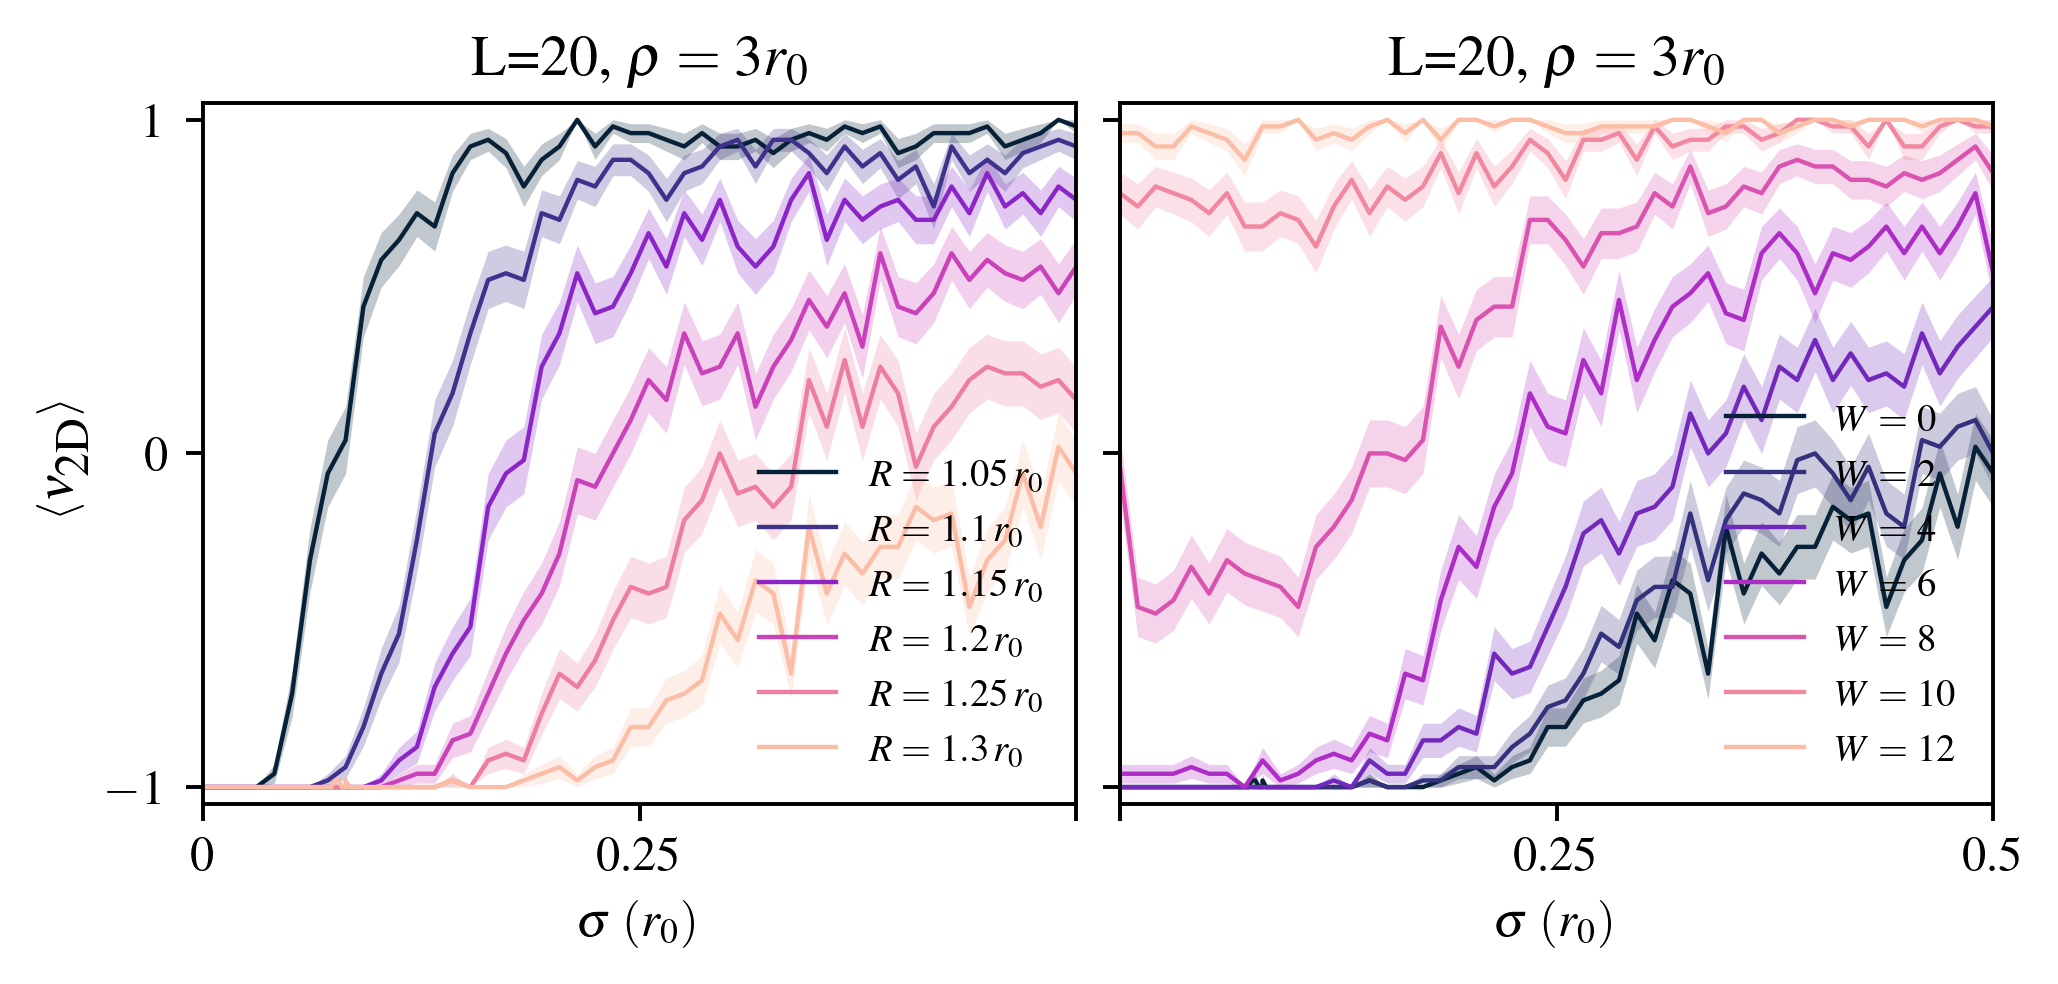

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(aps_figwidth, 2.6), sharey=True, dpi=350)
cmap = csh.bubblegum


def plot_family(axis, data, label_fmt):
    keys = sorted(data)
    for i, key in enumerate(keys):
        color = cmap(i / max(len(keys) - 1, 1))
        s, m, e = curve(data[key])
        axis.plot(s, m, color=color, linewidth=0.9, label=label_fmt(key), rasterized=True)
        axis.fill_between(s, m - e, m + e, color=color, alpha=0.25, linewidth=0, rasterized=True)


plot_family(ax[0], out_R, lambda R: rf"$R={R:g}\,r_0$")
plot_family(ax[1], out_W, lambda W: rf"$W={W:g}$")

ax[0].set_ylabel(r"$\langle \nu_{\textup{2D}} \rangle$")
ax[0].set_xlabel(r"$\sigma\ (r_0)$")
ax[1].set_xlabel(r"$\sigma\ (r_0)$")
for axis in ax:
    axis.set_xlim(0, 0.5)
    axis.legend(fontsize=8, frameon=False, loc="lower right")
ax[0].set_xticks([0, 0.25, 0.5])
ax[0].set_xticklabels(["0", "0.25", ""])  # avoid overlap with the right panel
ax[1].set_xticks([0, 0.25, 0.5])
ax[1].set_xticklabels(["", "0.25", "0.5"])
ax[0].set_ylim(-1.05, 1.05)
ax[0].set_yticks([-1, 0, 1])
fig.subplots_adjust(wspace=0.05)
ax[0].set_title(r"L=20, $\rho=3r_0$")
plt.title(r"L=20, $\rho=3r_0$")
plt.savefig(HERE / "fig_z2_vs_sigma.png",dpi=350, bbox_inches="tight")

In [7]:
# fig.savefig("z2_vs_sigma_R_W_L20_kshift3r0.png", bbox_inches="tight", dpi=350)